Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [1]:
# Librerías requeridas
# PyTorch para construir y entrenar las redes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Para descargar los recursos desde la red con proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Se descargan los recursos de NLTK si no están instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

# Semillas
torch.manual_seed(3)
np.random.seed(3)

# Se usa GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

# Librerías para el modelo con GloVe
import os
from collections import Counter
from gensim.models import KeyedVectors
import gensim.downloader as api

Usando dispositivo: cuda


### 2. Importar los datos

In [2]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    40000 non-null  str  
 1   label   40000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 50.6 MB


### 3. Exploración de datos

In [3]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [4]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

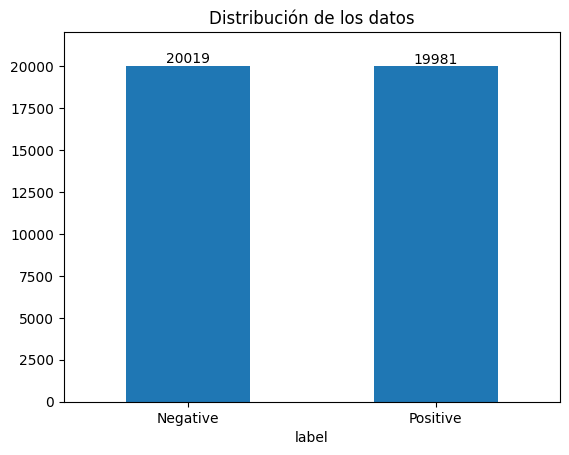

In [5]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # espacio para las etiquetas


In [6]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


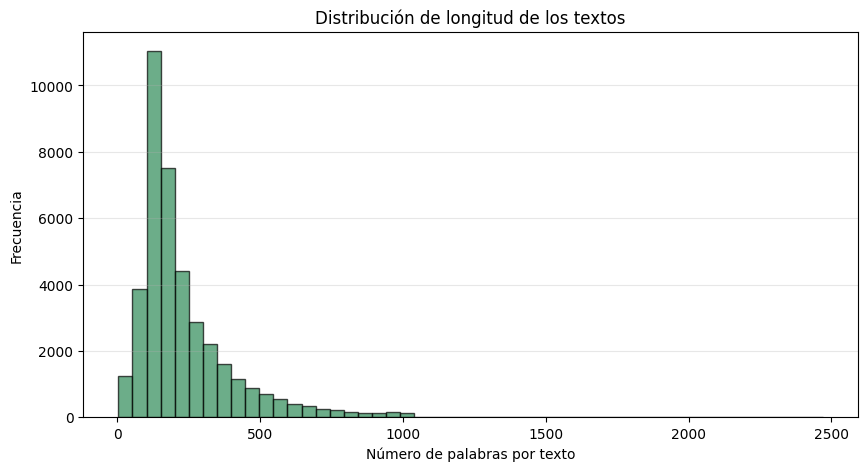

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [7]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Las clases están casi balanceadas (20.019 negativas y 19.981 positivas), así que no hizo falta balancear. No hay nulos, pero hay 277 reseñas repetidas que se quitan antes de dividir. Las reseñas tienen en promedio 231 palabras y la mediana es 173. La más corta tiene 4 palabras y la más larga 2.470, por eso el histograma tiene una cola larga a la derecha. Solo una reseña tiene menos de 5 palabras y 60 pasan de 1.000.

### 4. Separación de datos

Antes de dividir se quitan las reseñas duplicadas, para que una misma reseña no termine en entrenamiento y en prueba al mismo tiempo. Quedan 39.723 registros. Se dividen en 70 % entrenamiento (27.806), 15 % validación (5.958) y 15 % prueba (5.959), estratificando por la etiqueta para mantener la proporción de clases. Se usa la semilla 3.

In [8]:
# Se quitan los duplicados antes de dividir
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 3

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

La función `limpiar_texto` convierte entidades HTML como `&amp;`, quita etiquetas como `<br />` y las URLs y pasa el texto a minúsculas. Las negaciones contraídas se separan (por ejemplo *didn't* queda *did not*) y las demás contracciones, como *'s* o *'ll*, se borran. Después se dejan solo letras.

También se quitan las stopwords de NLTK y las palabras de una letra, pero se dejan *no*, *nor*, *not*, *but*, *very*, *too*, *against* y *only* porque cambian el sentido de la reseña. Por último se aplica el stemmer de Porter, que deja cada palabra en su raíz (*movies* queda *movi*). El resultado se guarda en la columna `palabras_limpias` de los tres conjuntos.

In [9]:
import re
import html

# Se conservan las negaciones y palabras que cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)  # html
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)  # urls
    texto = texto.lower().replace('\u2019', "'")  # minúsculas
    texto = re.sub(r"\bwon't\b", 'will not', texto)  # negaciones
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)  # contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)  # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    # Retorna la lista de palabras limpias
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

# Limpieza de train, validación y prueba
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Vocabulario y secuencias

El vocabulario se arma solo con entrenamiento, para no usar información de validación ni de prueba. El índice 0 es el padding, el 1 las palabras desconocidas y los demás las 19.998 palabras más frecuentes, en total 20.000 índices. Cada reseña queda como una secuencia de 300 índices. Si es más corta se completa con ceros al inicio y si es más larga se corta y se deja el comienzo. Los lotes son de 128 en entrenamiento y de 256 en validación y prueba.

In [10]:
MAX_VOCAB = 20000
MAX_LEN = 300
EMB_DIM = 300

# 0 = padding, 1 = desconocida
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]   # se deja el inicio de la reseña
    return [0] * (MAX_LEN - len(ids)) + ids

def a_tensores(df):
    X = torch.tensor([codificar(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 7. Embeddings GloVe

Se usan los vectores preentrenados de GloVe de 300 dimensiones. Si `glove.6B.300d.txt` está en la carpeta se carga de ahí y si no se descarga con gensim (`glove-wiki-gigaword-300`). La matriz de embeddings sigue el orden del vocabulario. Las palabras que no están en GloVe reciben un vector aleatorio con la misma desviación estándar de GloVe y el padding queda en ceros. Como las palabras pasaron por stemming, muchas no aparecen en GloVe, y eso puede afectar a este modelo.

In [11]:
if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas])
rng = np.random.default_rng(SEED)

emb_matrix = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM)).astype(np.float32)
emb_matrix[0] = 0
for palabra in encontradas:
    emb_matrix[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 14,144 de 19,998


### 8. Modelo

La primera capa es el embedding de 300 dimensiones, que se inicializa con la matriz de GloVe. Así el modelo arranca con relaciones entre palabras ya aprendidas. La capa se deja entrenable para que se ajuste a las reseñas y después va un dropout de 0.3 para reducir el sobreajuste.

Luego hay dos capas LSTM de 128 unidades con dropout de 0.3 entre ellas. Se usó LSTM y no una RNN simple porque las reseñas son largas (hasta 300 tokens) y la RNN simple pierde lo del principio por el desvanecimiento del gradiente.

Encima de la LSTM se puso una capa de atención. Una capa lineal le asigna un puntaje a cada palabra, con softmax esos puntajes se vuelven pesos y se saca el promedio ponderado de las salidas de la LSTM. Con esto el modelo no se queda solo con el último estado y puede fijarse más en palabras como *awful* o *masterpiece*. Las posiciones de padding se enmascaran.

Al final hay otro dropout de 0.3 y una neurona con sigmoide que da la probabilidad de que la reseña sea positiva. Con 0.5 o más se toma como positiva. La pérdida es `BCELoss`.

Se entrena con Adam (lr = 0.001, weight decay = 1e-5) y se recorta la norma del gradiente a 1.0 porque en las LSTM los gradientes a veces se disparan. El modelo de Word2Vec tiene la misma arquitectura, así se pueden comparar los dos embeddings.

In [12]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.atencion = nn.Linear(hidden_dim, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mascara = (x != 0)
        emb = self.emb_dropout(self.embedding(x))
        salida, _ = self.lstm(emb)

        # atención (sin contar el padding)
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.dropout(h)
        return self.sigmoid(self.fc(h)).squeeze(1)

torch.manual_seed(SEED)
modelo = SentimentLSTM(emb_matrix.shape[0], EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(emb_matrix))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 300, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 6,352,514


### 9. Entrenamiento con validación

En cada época se entrena con train y se evalúa con validación. Se guarda el modelo con la menor pérdida de validación y si no mejora en 10 épocas se detiene el entrenamiento (máximo 50 épocas). Además, `ReduceLROnPlateau` baja la tasa de aprendizaje a la mitad cuando la pérdida de validación se estanca. Al final se cargan los pesos del mejor modelo y se grafican la pérdida y el accuracy.

In [13]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 10

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.4276 acc 0.7993 | val loss 0.3152 acc 0.8687 | lr 1.0e-03
Época  2 | train loss 0.2584 acc 0.8957 | val loss 0.3018 acc 0.8790 | lr 1.0e-03
Época  3 | train loss 0.1980 acc 0.9257 | val loss 0.2812 acc 0.8897 | lr 1.0e-03
Época  4 | train loss 0.1563 acc 0.9431 | val loss 0.3076 acc 0.8795 | lr 1.0e-03
Época  5 | train loss 0.1197 acc 0.9575 | val loss 0.3297 acc 0.8845 | lr 5.0e-04
Época  6 | train loss 0.0775 acc 0.9754 | val loss 0.3963 acc 0.8790 | lr 5.0e-04
Época  7 | train loss 0.0596 acc 0.9812 | val loss 0.4561 acc 0.8773 | lr 2.5e-04
Época  8 | train loss 0.0442 acc 0.9869 | val loss 0.4977 acc 0.8758 | lr 2.5e-04
Época  9 | train loss 0.0357 acc 0.9892 | val loss 0.5366 acc 0.8756 | lr 1.3e-04
Época 10 | train loss 0.0314 acc 0.9914 | val loss 0.5681 acc 0.8751 | lr 1.3e-04
Época 11 | train loss 0.0291 acc 0.9921 | val loss 0.5768 acc 0.8743 | lr 6.3e-05
Época 12 | train loss 0.0266 acc 0.9932 | val loss 0.5811 acc 0.8729 | lr 6.3e-05
Época 13 | train

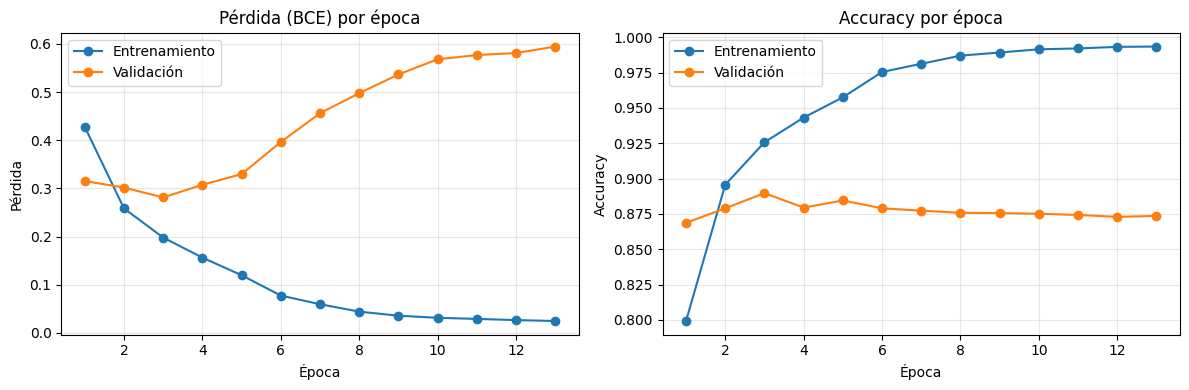

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 10. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el conjunto de prueba (15 %), que no se usó para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall, F1-score y la matriz de confusión.

Accuracy : 0.8929
Precisión: 0.8751
Recall   : 0.9173
F1-score : 0.8957

              precision    recall  f1-score   support

    Negativa     0.9127    0.8685    0.8900      2973
    Positiva     0.8751    0.9173    0.8957      2986

    accuracy                         0.8929      5959
   macro avg     0.8939    0.8929    0.8929      5959
weighted avg     0.8938    0.8929    0.8929      5959



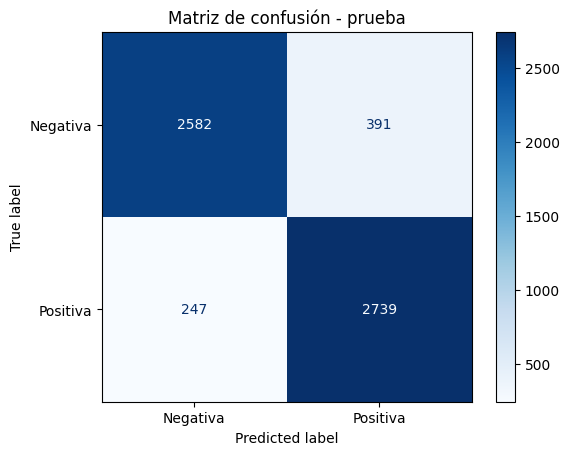

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}")
print()
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba")
plt.show()

### 11. Pérdida en test, AUC y accuracy por longitud (GloVe)

Se calcula la pérdida en prueba, para ver si se parece a la de validación, y el AUC con su curva ROC. También se mira el accuracy por rangos de longitud de la reseña. La idea es ver si el modelo se equivoca más en las reseñas cortas o en las de más de 300 tokens, que se cortan.

Pérdida test: 0.2664 | mejor pérdida validación: 0.2812
AUC test: 0.9591
         reseñas  accuracy
rango                     
0-50         652    0.9064
51-100      2571    0.8911
101-200     1817    0.8866
201-300      542    0.9133
>300         377    0.8833


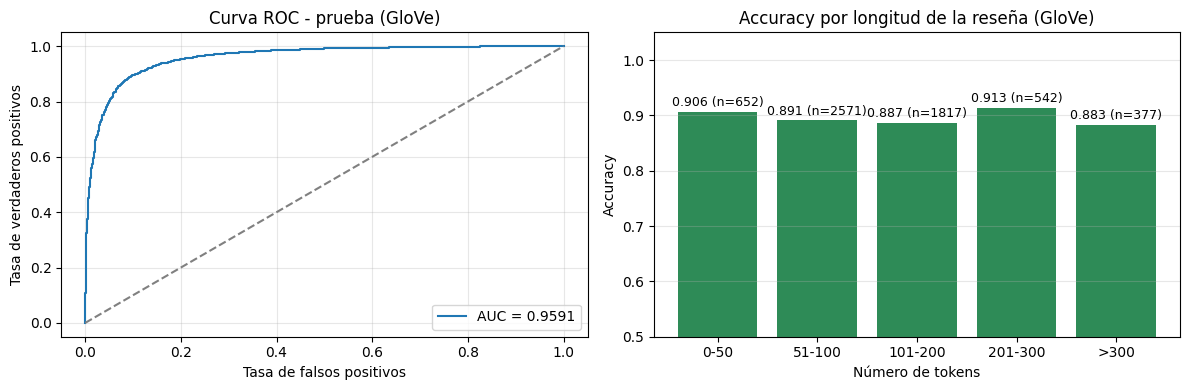

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve

# pérdida en test (el modelo ya devuelve probabilidades)
test_loss = criterio(torch.tensor(probs), torch.tensor(y_real, dtype=torch.float32)).item()
auc = roc_auc_score(y_real, probs)
print(f"Pérdida test: {test_loss:.4f} | mejor pérdida validación: {min(historial['val_loss']):.4f}")
print(f"AUC test: {auc:.4f}")

# test_loader no tiene shuffle, el orden es el mismo de test_GHI
resultados = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real,
    "pred": y_pred,
    "prob": probs,
})
resultados["acierto"] = (resultados["real"] == resultados["pred"]).astype(int)

cortes = [0, 50, 100, 200, 300, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-300", ">300"]
resultados["rango"] = pd.cut(resultados["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud = resultados.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                               accuracy=("acierto", "mean"))
print(por_longitud.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real, probs)
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba (GloVe)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud["accuracy"], por_longitud["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña (GloVe)")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 12. Ejemplos de errores (GloVe)

Se revisan los errores en los que el modelo estaba más seguro: las reseñas negativas con mayor probabilidad de ser positivas (falsos positivos) y las positivas con menor probabilidad (falsos negativos). Se muestran 5 de cada uno.

In [17]:
resultados["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp = resultados[(resultados["real"] == 0) & (resultados["pred"] == 1)]
fn = resultados[(resultados["real"] == 1) & (resultados["pred"] == 0)]
print("Falsos positivos:", len(fp))
print("Falsos negativos:", len(fn))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 391
Falsos negativos: 247
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.998 | Tokens: 73
This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you right away, and holds you at the edge of your seat throughout the film. He provides wonderful insight into the world of the trainables and allows the audience to really 'connect' with internal horror this film exhibits. The script itself holds the movie
Probabilidad: 0.998 | Tokens: 13
Great movie - especially the music - Etta James - "At Last". This speaks volumes when you have finally found that special someone.
Probabilidad: 0.997 | Tokens: 24
Once in a while, a movie will sweep along that stuns you, draws you in, awes you, and, in the end, leaves you with a renewed belief in the human race f

## Modelo con embeddings Word2Vec (comparación con GloVe 300d)

Para comparar se entrena otro modelo, ahora con embeddings Word2Vec de 100 dimensiones entrenados con las reseñas de entrenamiento. Se usan los mismos conjuntos y el mismo vocabulario. Las variables de esta parte terminan en `_w2v` para no sobrescribir los resultados de GloVe.

### 13. Embeddings Word2Vec

Word2Vec se entrena solo con las reseñas de entrenamiento, con vectores de 100 dimensiones, ventana de 5 y `min_count=1`.

In [18]:
from gensim.models import Word2Vec

EMB_DIM_W2V = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM_W2V,
    window=5,
    min_count=1,
    workers=4,
    seed=SEED,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 53,683
Similares a 'great': [('fine', 0.7558800578117371), ('excel', 0.7525305151939392), ('fantast', 0.7269195318222046), ('brilliant', 0.6820196509361267), ('good', 0.6723681688308716)]


### 14. Matriz con embeddings y tensores

Se usa el mismo vocabulario de 20.000 índices y las secuencias se arman igual que para GloVe (300 índices, padding al inicio y se deja el comienzo de las reseñas largas). Cada fila de la matriz toma el vector de Word2Vec de su palabra y el padding queda en ceros. Como Word2Vec se entrenó con `min_count=1`, todas las palabras del vocabulario tienen vector. Los lotes son de 128 en entrenamiento y de 256 en validación y prueba.

In [19]:
MAX_LEN_W2V = 300
VOCAB_SIZE_W2V = len(word2idx) + 2

def codificar_w2v(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN_W2V]
    # padding al inicio
    return [0] * (MAX_LEN_W2V - len(ids)) + ids

# Matriz de embeddings con los vectores de Word2Vec
matriz_emb_w2v = np.random.normal(0, 0.1, (VOCAB_SIZE_W2V, EMB_DIM_W2V)).astype("float32")
matriz_emb_w2v[0] = 0.0  # padding
encontradas_w2v = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb_w2v[idx] = w2v.wv[palabra]
        encontradas_w2v += 1
print(f"Palabras con vector Word2Vec: {encontradas_w2v:,} / {len(word2idx):,}")

def a_tensores_w2v(frame):
    X = torch.tensor([codificar_w2v(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train_w2v, y_train_w2v = a_tensores_w2v(train_GHI)
X_val_w2v, y_val_w2v = a_tensores_w2v(val_GHI)
X_test_w2v, y_test_w2v = a_tensores_w2v(test_GHI)

train_loader_w2v = DataLoader(TensorDataset(X_train_w2v, y_train_w2v), batch_size=128, shuffle=True)
val_loader_w2v = DataLoader(TensorDataset(X_val_w2v, y_val_w2v), batch_size=256)
test_loader_w2v = DataLoader(TensorDataset(X_test_w2v, y_test_w2v), batch_size=256)
print(X_train_w2v.shape, X_val_w2v.shape, X_test_w2v.shape)

Palabras con vector Word2Vec: 19,998 / 19,998
torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 15. Modelo Word2Vec

Se usa la misma clase `SentimentLSTM` del modelo con GloVe. Solo cambia el embedding, que en este caso es de 100 dimensiones y se inicializa con los vectores de Word2Vec. El resto se mantiene: dropout de 0.3, dos capas LSTM de 128 unidades, atención y la neurona de salida con sigmoide. El entrenamiento también es igual, con `BCELoss`, Adam (lr = 0.001, weight decay = 1e-5), `ReduceLROnPlateau` y recorte del gradiente a 1.0.

In [20]:
# misma clase SentimentLSTM del modelo con GloVe
torch.manual_seed(SEED)
modelo_w2v = SentimentLSTM(VOCAB_SIZE_W2V, EMB_DIM_W2V).to(device)
modelo_w2v.embedding.weight.data.copy_(torch.tensor(matriz_emb_w2v))
modelo_w2v.embedding.weight.requires_grad = True
criterio_w2v = nn.BCELoss()
optimizador_w2v = optim.Adam(modelo_w2v.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler_w2v = optim.lr_scheduler.ReduceLROnPlateau(optimizador_w2v, mode="min", factor=0.5, patience=1)

print(modelo_w2v)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_w2v.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,250,114


### 16. Entrenamiento con validación (Word2Vec)

Se entrena igual que el modelo con GloVe. Se guarda el modelo con menor pérdida de validación, con early stopping de paciencia 10, máximo 50 épocas y `ReduceLROnPlateau`. Al final se cargan los mejores pesos y se grafican las curvas.

In [21]:
def ejecutar_epoca_w2v(loader, entrenar):
    modelo_w2v.train() if entrenar else modelo_w2v.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_w2v(xb)
            perdida = criterio_w2v(prob, yb)
            if entrenar:
                optimizador_w2v.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_w2v.parameters(), 1.0)
                optimizador_w2v.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_W2V = 50
PACIENCIA_W2V = 10

historial_w2v = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_w2v = float("inf")
mejor_estado_w2v = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_W2V + 1):
    tr_loss, tr_acc = ejecutar_epoca_w2v(train_loader_w2v, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_w2v(val_loader_w2v, entrenar=False)
    scheduler_w2v.step(va_loss)
    for k, v in zip(historial_w2v, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_w2v[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_w2v.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_w2v:
        mejor_val_loss_w2v = va_loss
        mejor_estado_w2v = copy.deepcopy(modelo_w2v.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_W2V:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA_W2V} épocas")
            break

modelo_w2v.load_state_dict(mejor_estado_w2v)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_w2v:.4f}")

Época  1 | train loss 0.3953 acc 0.8159 | val loss 0.3075 acc 0.8677 | lr 1.0e-03
Época  2 | train loss 0.2987 acc 0.8757 | val loss 0.2980 acc 0.8761 | lr 1.0e-03
Época  3 | train loss 0.2506 acc 0.8983 | val loss 0.2580 acc 0.8946 | lr 1.0e-03
Época  4 | train loss 0.2050 acc 0.9189 | val loss 0.2566 acc 0.8944 | lr 1.0e-03
Época  5 | train loss 0.1660 acc 0.9391 | val loss 0.2730 acc 0.8985 | lr 1.0e-03
Época  6 | train loss 0.1309 acc 0.9527 | val loss 0.2853 acc 0.8969 | lr 5.0e-04
Época  7 | train loss 0.0932 acc 0.9679 | val loss 0.3145 acc 0.8922 | lr 5.0e-04
Época  8 | train loss 0.0794 acc 0.9732 | val loss 0.3623 acc 0.8842 | lr 2.5e-04
Época  9 | train loss 0.0608 acc 0.9806 | val loss 0.4135 acc 0.8865 | lr 2.5e-04
Época 10 | train loss 0.0540 acc 0.9821 | val loss 0.4169 acc 0.8835 | lr 1.3e-04
Época 11 | train loss 0.0486 acc 0.9847 | val loss 0.4247 acc 0.8850 | lr 1.3e-04
Época 12 | train loss 0.0472 acc 0.9849 | val loss 0.4286 acc 0.8837 | lr 6.3e-05
Época 13 | train

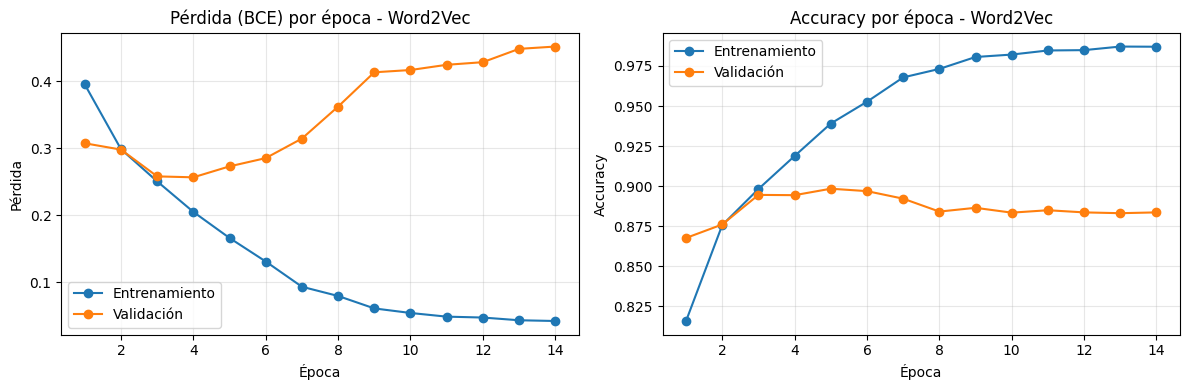

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial_w2v["train_loss"]) + 1)

axes[0].plot(epocas_x, historial_w2v["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial_w2v["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época - Word2Vec")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial_w2v["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial_w2v["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época - Word2Vec")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 17. Evaluación en el conjunto de prueba (Word2Vec)

El mejor modelo de Word2Vec se evalúa con el mismo conjunto de prueba que se usó para GloVe.

Accuracy : 0.9028
Precisión: 0.9037
Recall   : 0.9022
F1-score : 0.9030
AUC      : 0.9653
Pérdida test: 0.2403 | mejor pérdida validación: 0.2566

              precision    recall  f1-score   support

    Negativa     0.9019    0.9035    0.9027      2973
    Positiva     0.9037    0.9022    0.9030      2986

    accuracy                         0.9028      5959
   macro avg     0.9028    0.9028    0.9028      5959
weighted avg     0.9028    0.9028    0.9028      5959



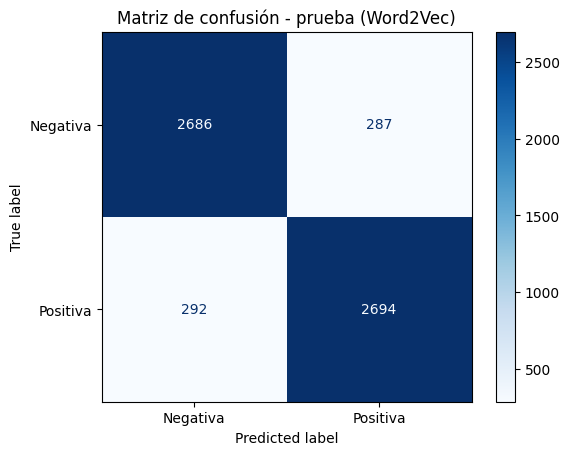

In [23]:
modelo_w2v.eval()
probs_w2v, reales_w2v = [], []
with torch.no_grad():
    for xb, yb in test_loader_w2v:
        probs_w2v.append(modelo_w2v(xb.to(device)).cpu())
        reales_w2v.append(yb)
probs_w2v = torch.cat(probs_w2v).numpy()
y_real_w2v = torch.cat(reales_w2v).numpy().astype(int)
y_pred_w2v = (probs_w2v >= 0.5).astype(int)

test_loss_w2v = criterio_w2v(torch.tensor(probs_w2v), torch.tensor(y_real_w2v, dtype=torch.float32)).item()
auc_w2v = roc_auc_score(y_real_w2v, probs_w2v)

print(f"Accuracy : {accuracy_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Precisión: {precision_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Recall   : {recall_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"F1-score : {f1_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"AUC      : {auc_w2v:.4f}")
print(f"Pérdida test: {test_loss_w2v:.4f} | mejor pérdida validación: {mejor_val_loss_w2v:.4f}\n")
print(classification_report(y_real_w2v, y_pred_w2v, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real_w2v, y_pred_w2v),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba (Word2Vec)")
plt.show()

### 18. Pérdida en test, AUC y accuracy por longitud (Word2Vec)

Se repite el análisis por longitud que se hizo con GloVe, para ver si los dos modelos fallan en el mismo tipo de reseñas. La pérdida en test y el AUC ya se calcularon en la evaluación, así que aquí se grafican la curva ROC y el accuracy por rango de longitud.

         reseñas  accuracy
rango                     
0-50         652    0.8957
51-100      2571    0.8993
101-200     1817    0.9070
201-300      542    0.9170
>300         377    0.8992


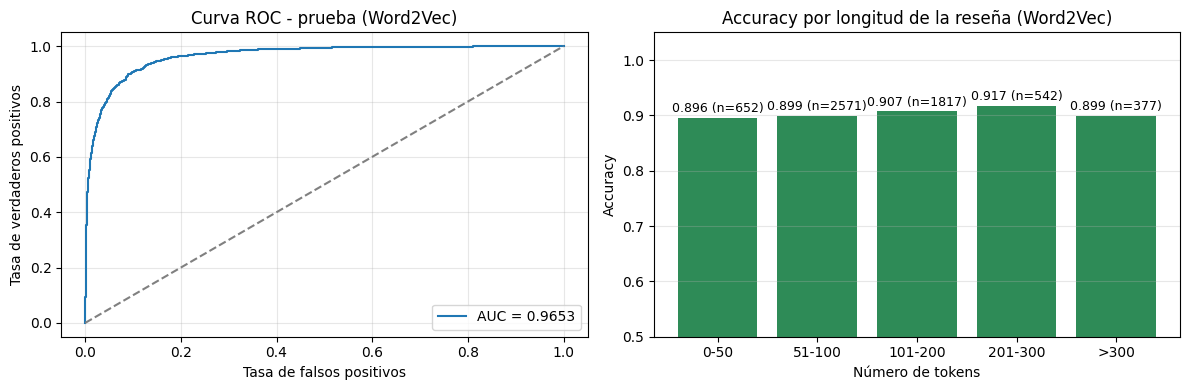

In [24]:
# test_loader_w2v no tiene shuffle, el orden es el mismo de test_GHI
resultados_w2v = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real_w2v,
    "pred": y_pred_w2v,
    "prob": probs_w2v,
})
resultados_w2v["acierto"] = (resultados_w2v["real"] == resultados_w2v["pred"]).astype(int)

cortes = [0, 50, 100, 200, 300, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-300", ">300"]
resultados_w2v["rango"] = pd.cut(resultados_w2v["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud_w2v = resultados_w2v.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                                       accuracy=("acierto", "mean"))
print(por_longitud_w2v.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real_w2v, probs_w2v)
axes[0].plot(fpr, tpr, label=f"AUC = {auc_w2v:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba (Word2Vec)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud_w2v["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud_w2v["accuracy"], por_longitud_w2v["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña (Word2Vec)")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 19. Ejemplos de errores (Word2Vec)

Igual que con GloVe, se muestran los 5 falsos positivos y los 5 falsos negativos en los que el modelo estaba más seguro. Sirve para ver si los dos modelos se equivocan en reseñas parecidas.

In [25]:
resultados_w2v["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp_w2v = resultados_w2v[(resultados_w2v["real"] == 0) & (resultados_w2v["pred"] == 1)]
fn_w2v = resultados_w2v[(resultados_w2v["real"] == 1) & (resultados_w2v["pred"] == 0)]
print("Falsos positivos:", len(fp_w2v))
print("Falsos negativos:", len(fn_w2v))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp_w2v.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn_w2v.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 287
Falsos negativos: 292
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.998 | Tokens: 73
This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you right away, and holds you at the edge of your seat throughout the film. He provides wonderful insight into the world of the trainables and allows the audience to really 'connect' with internal horror this film exhibits. The script itself holds the movie
Probabilidad: 0.997 | Tokens: 13
Great movie - especially the music - Etta James - "At Last". This speaks volumes when you have finally found that special someone.
Probabilidad: 0.992 | Tokens: 24
Definitely not worth the rental, but if you catch it on cable, you'll be pleasantly surprised by the cameos--Iman's appearance is especially self-depre

### 20. Comparación GloVe 300d vs. Word2Vec

Se comparan las métricas de prueba y las curvas ROC de los dos modelos. Los dos usan `BCELoss`, así que la pérdida en test también se puede comparar. Como la arquitectura, el largo de las secuencias, la pérdida y el early stopping son los mismos, la diferencia está en el embedding. GloVe es preentrenado y tiene 300 dimensiones, mientras que Word2Vec tiene 100 dimensiones y se entrenó con las mismas reseñas.

                                         Accuracy  Precisión  Recall  \
GloVe 300d (LSTM 2 capas + atención)       0.8929     0.8751  0.9173   
Word2Vec 100d (LSTM 2 capas + atención)    0.9028     0.9037  0.9022   

                                         F1-score     AUC  Pérdida test  \
GloVe 300d (LSTM 2 capas + atención)       0.8957  0.9591        0.2664   
Word2Vec 100d (LSTM 2 capas + atención)    0.9030  0.9653        0.2403   

                                         Épocas  
GloVe 300d (LSTM 2 capas + atención)       13.0  
Word2Vec 100d (LSTM 2 capas + atención)    14.0  


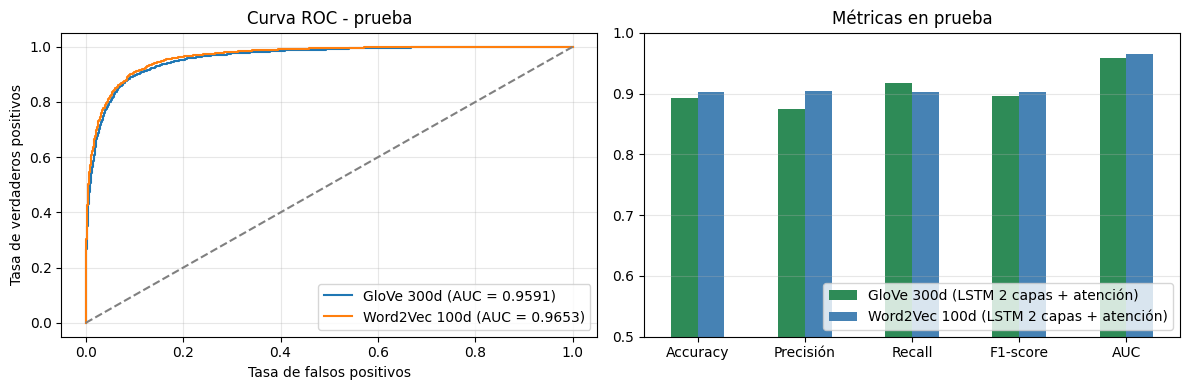

In [26]:
def metricas(y_true, y_hat, prob, perdida, historial_modelo):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precisión": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-score": f1_score(y_true, y_hat),
        "AUC": roc_auc_score(y_true, prob),
        "Pérdida test": perdida,
        "Épocas": len(historial_modelo["train_loss"]),
    }

comparacion = pd.DataFrame({
    "GloVe 300d (LSTM 2 capas + atención)": metricas(y_real, y_pred, probs, test_loss, historial),
    "Word2Vec 100d (LSTM 2 capas + atención)": metricas(y_real_w2v, y_pred_w2v, probs_w2v, test_loss_w2v, historial_w2v),
}).T
print(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, y_t, p in [("GloVe 300d", y_real, probs), ("Word2Vec 100d", y_real_w2v, probs_w2v)]:
    fpr, tpr, _ = roc_curve(y_t, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_t, p):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(); axes[0].grid(alpha=0.3)

cols = ["Accuracy", "Precisión", "Recall", "F1-score", "AUC"]
comparacion[cols].T.plot(kind="bar", ax=axes[1], rot=0, color=["seagreen", "steelblue"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Métricas en prueba")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()